<a href="https://colab.research.google.com/github/alissonjsb4/applied-computational-intelligence/blob/main/homework02/homework2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HOMEWORK 02 INTELIGÊNCIA COMPUTACIONAL APLICADA

Autores:

Icaro Adriano 609310 (Departamento de Engenharia de Teleinformatica)

Matheus Reis 571954 (Departamento de Engenharia de Teleinformatica)

Alisson Jaime 555083 (Departamento de Engenharia de Teleinformatica)

Vinicius Alexandre Gomes do Nascimento 568594 (Departamento de Engenharia de Teleinformatica)

# 0. ANÁLISE EXPLORATÓRIA E PRÉ-PROCESSAMENTO

## Descrição do dataset

O dataset de solubilidade tem N = 1267 compostos químicos, já separados em treino (`solTrainX`,
`solTrainY`, Ntr = 951) e teste (`solTestX`, `solTestY`, Nts = 316). Cada composto tem D = 228
preditores:

- 208 *fingerprints* binários (`FP001` a `FP208`), que indicam presença ou ausência de uma subestrutura química;
- 16 contagens (número de átomos, de ligações, de anéis, de átomos de cloro etc.);
- 4 descritores contínuos (`MolWeight`, `HydrophilicFactor`, `SurfaceArea1`, `SurfaceArea2`).

A saída é a solubilidade do composto (em escala log). Os arquivos são texto separado por tabulação, com o
nome da linha na primeira coluna.

Um detalhe importante: o nome das linhas nos arquivos X é o identificador original do composto
(661, 662, 663, ...), enquanto nos arquivos Y é só a posição (1, 2, 3, ...). Se deixarmos o pandas
alinhar pelo índice, ele cruza X e Y errado. Por isso zeramos o índice dos dois logo na leitura, e o
pareamento passa a ser pela ordem das linhas, que é o correto.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

os.makedirs('figuras', exist_ok=True)

def salvar_figura(nome, dpi=120):
    """Salva a figura atual em figuras/<nome>.png para ser usada no artigo."""
    plt.savefig(os.path.join('figuras', nome + '.png'), dpi=dpi, bbox_inches='tight')
    return

def ler(arquivo):
    # sep='\t' porque o arquivo e separado por tabulacao; reset_index descarta o nome da linha
    return pd.read_csv(os.path.join('dataset', arquivo), sep='\t').reset_index(drop=True)

X_treino = ler('solTrainX.txt')
X_teste = ler('solTestX.txt')
y_treino = ler('solTrainY.txt')['x'].rename('Solubilidade')
y_teste = ler('solTestY.txt')['x'].rename('Solubilidade')

print('X treino:', X_treino.shape, '  y treino:', y_treino.shape)
print('X teste: ', X_teste.shape, '  y teste: ', y_teste.shape)
print('Valores faltantes:', X_treino.isna().sum().sum() + X_teste.isna().sum().sum())

X treino: (951, 228)   y treino: (951,)
X teste:  (316, 228)   y teste:  (316,)
Valores faltantes: 0


Separamos os preditores pelo tipo. Os binários são as colunas `FP`; o resto (16 contagens + 4
contínuos) chamamos de preditores não binários. Conferimos também que os `FP` só assumem 0 ou 1.

In [2]:
binarios = [c for c in X_treino.columns if c.startswith('FP')]
nao_binarios = [c for c in X_treino.columns if not c.startswith('FP')]
continuos = ['MolWeight', 'HydrophilicFactor', 'SurfaceArea1', 'SurfaceArea2']
contagens = [c for c in nao_binarios if c not in continuos]

print('Binarios:   ', len(binarios))
print('Contagens:  ', len(contagens), contagens)
print('Continuos:  ', len(continuos), continuos)
print('FP so tem 0/1?', X_treino[binarios].isin([0, 1]).all().all())

Binarios:    208
Contagens:   16 ['NumAtoms', 'NumNonHAtoms', 'NumBonds', 'NumNonHBonds', 'NumMultBonds', 'NumRotBonds', 'NumDblBonds', 'NumAromaticBonds', 'NumHydrogen', 'NumCarbon', 'NumNitrogen', 'NumOxygen', 'NumSulfer', 'NumChlorine', 'NumHalogen', 'NumRings']
Continuos:   4 ['MolWeight', 'HydrophilicFactor', 'SurfaceArea1', 'SurfaceArea2']
FP so tem 0/1? True


Toda a análise exploratória abaixo é feita **só com o conjunto de treino**. O teste fica guardado
para a avaliação dos modelos; ele só é tocado para aplicar a mesma transformação estimada no treino.

## Distribuição da saída

Antes dos preditores, uma olhada rápida na solubilidade.

count    951.000
mean      -2.719
std        2.047
min      -11.620
25%       -3.955
50%       -2.510
75%       -1.360
max        1.580
assimetria: -0.671


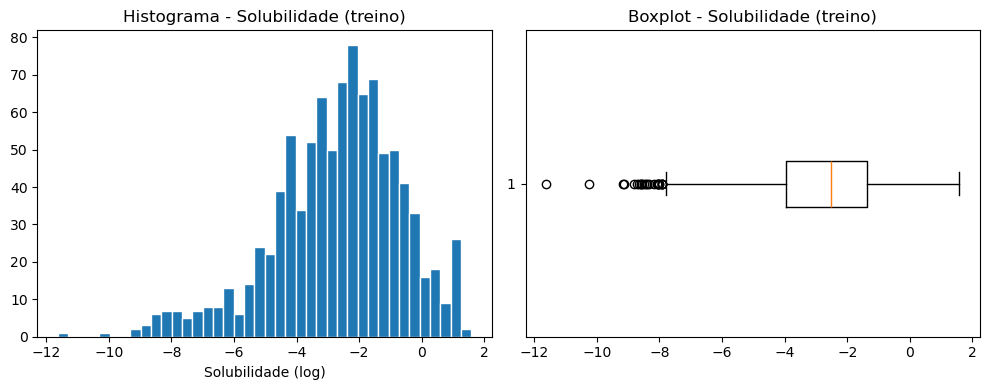

In [3]:
print(y_treino.describe().round(3).to_string())
print('assimetria:', round(y_treino.skew(), 3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(y_treino, bins=40, edgecolor='white')
axes[0].set_title('Histograma - Solubilidade (treino)')
axes[0].set_xlabel('Solubilidade (log)')
axes[1].boxplot(y_treino, vert=False)
axes[1].set_title('Boxplot - Solubilidade (treino)')
plt.tight_layout()
salvar_figura('hist_solubilidade')
plt.show()

A solubilidade vai de cerca de -11,6 a 1,6, com média -2,7. A distribuição é razoavelmente simétrica
(assimetria por volta de -0,67), com uma cauda à esquerda formada por poucos compostos muito
insolúveis. Não vemos necessidade de transformar a saída.

## Assimetria dos preditores

Os 208 preditores binários não são transformados: uma variável 0/1 tem só dois valores, e qualquer
transformação monotônica apenas troca o rótulo dos dois níveis, sem mudar a forma da distribuição. A
assimetria deles reflete só a frequência da subestrutura (a maioria aparece em poucos compostos).

O foco então são os 20 preditores não binários. Abaixo os histogramas e a assimetria de cada um na
escala original.

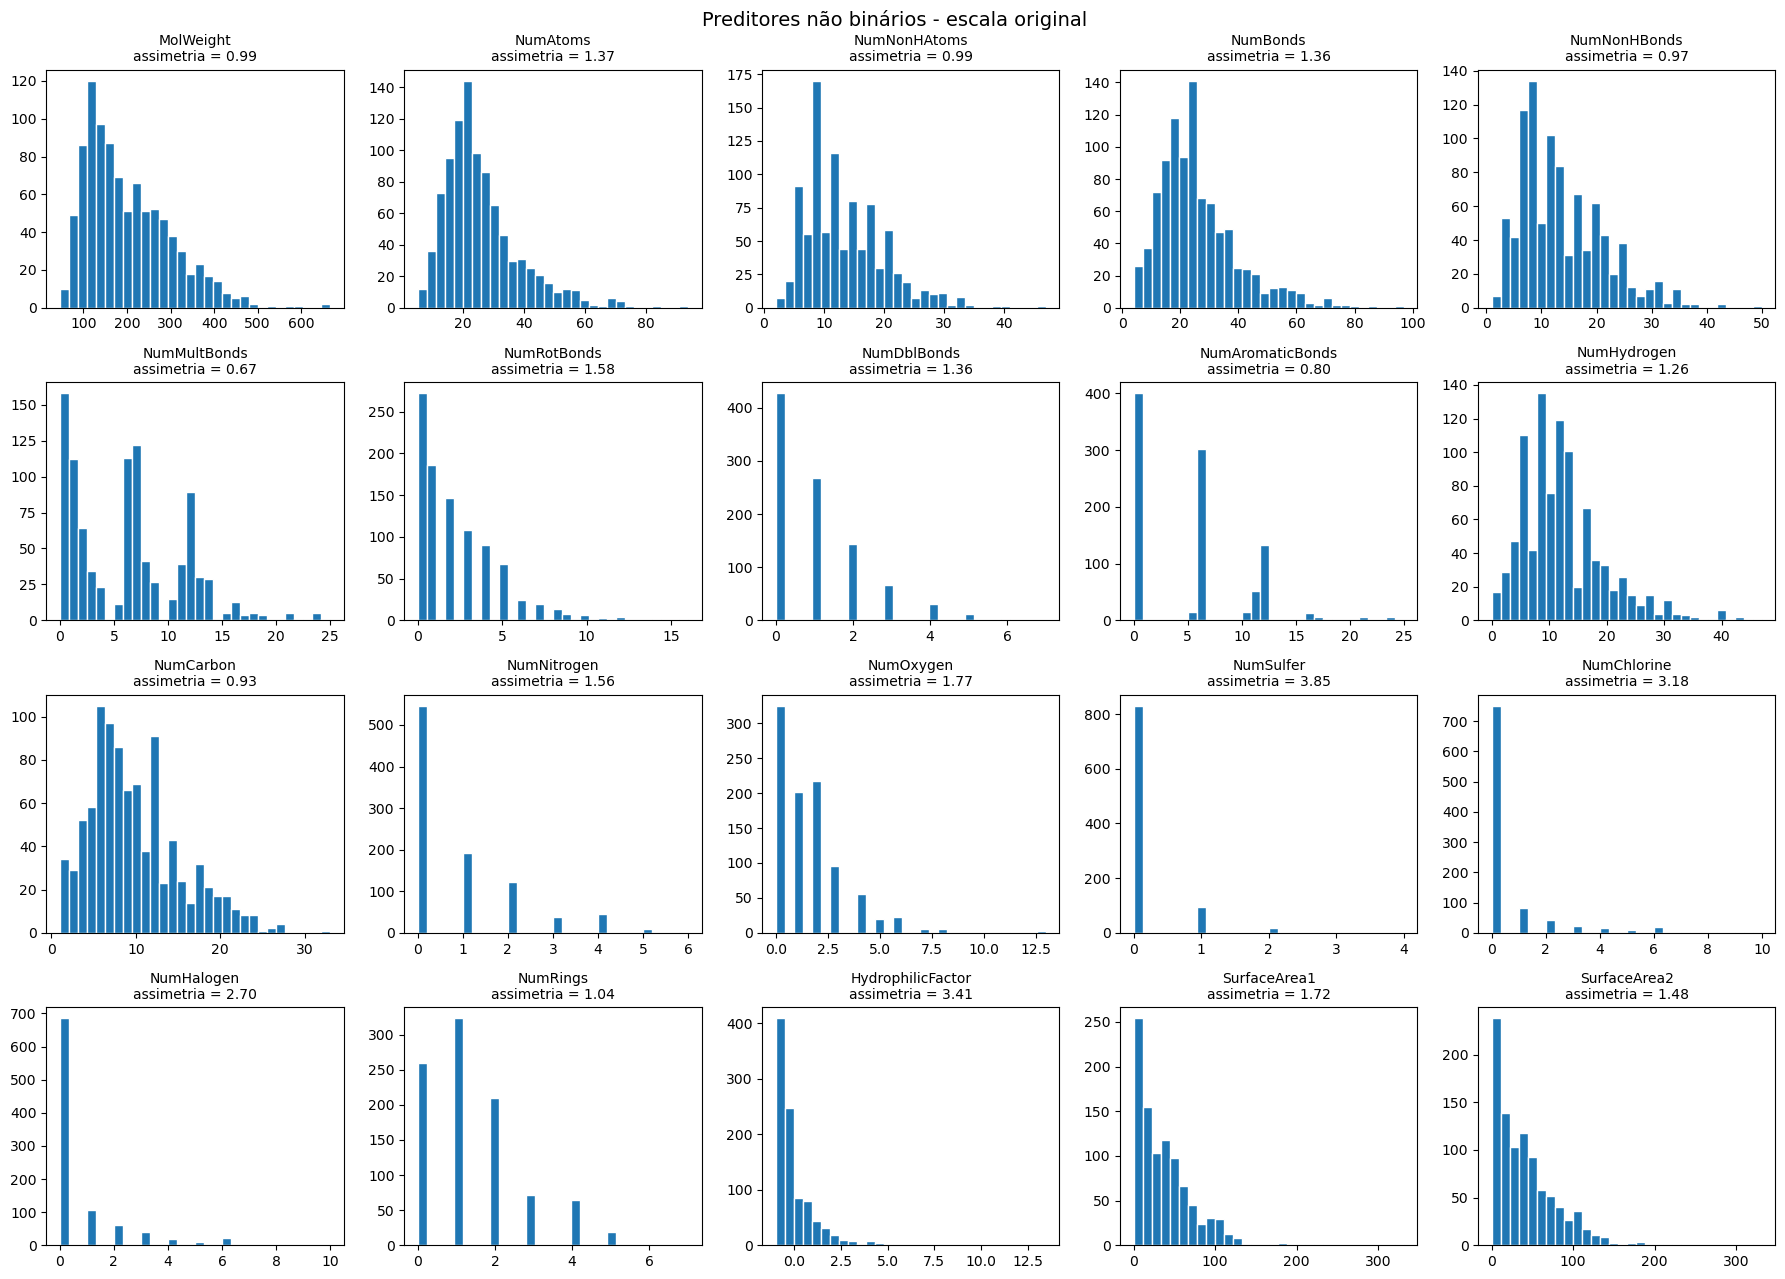

Frequencia media dos FP (fracao de compostos com a subestrutura): 0.194
Assimetria dos FP: mediana = 2.19, max = 4.85


In [4]:
def grade_histogramas(dados, colunas, titulo, nome_figura):
    fig, axes = plt.subplots(4, 5, figsize=(18, 13))
    for ax, coluna in zip(axes.ravel(), colunas):
        ax.hist(dados[coluna], bins=30, edgecolor='white')
        ax.set_title('%s\nassimetria = %.2f' % (coluna, dados[coluna].skew()), fontsize=10)
    fig.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    salvar_figura(nome_figura)
    plt.show()
    return

grade_histogramas(X_treino, nao_binarios, 'Preditores não binários - escala original', 'hist_originais')

print('Frequencia media dos FP (fracao de compostos com a subestrutura): %.3f' % X_treino[binarios].mean().mean())
print('Assimetria dos FP: mediana = %.2f, max = %.2f' % (X_treino[binarios].skew().median(), X_treino[binarios].skew().max()))

Todos os 20 preditores não binários têm assimetria positiva, isto é, cauda longa à direita. É o
esperado para contagens e tamanhos moleculares: a maioria dos compostos é pequena e alguns poucos são
bem maiores. Os casos mais extremos são `NumSulfer`, `HydrophilicFactor`, `NumChlorine` e
`NumHalogen`, todos com assimetria acima de 2,5.

### Transformação de Yeo-Johnson

A transformação clássica para remover assimetria é a de Box-Cox, mas ela só aceita valores
estritamente positivos. Aqui isso não serve: quase todas as contagens têm zeros (um composto pode não
ter nenhum átomo de enxofre) e o `HydrophilicFactor` tem valores negativos. Usamos então a
transformação de **Yeo-Johnson**, que é a extensão da Box-Cox para a reta real inteira:

$$
\psi(x, \lambda) =
\begin{cases}
\dfrac{(x+1)^\lambda - 1}{\lambda}, & x \ge 0,\ \lambda \ne 0 \\
\ln(x+1), & x \ge 0,\ \lambda = 0 \\
-\dfrac{(1-x)^{2-\lambda} - 1}{2-\lambda}, & x < 0,\ \lambda \ne 2 \\
-\ln(1-x), & x < 0,\ \lambda = 2
\end{cases}
$$

Para cada preditor, o parâmetro $\lambda$ é estimado por máxima verossimilhança no conjunto de treino
(`scipy.stats.yeojohnson`). O mesmo $\lambda$ é depois aplicado ao conjunto de teste, para que o teste
não influencie em nada o pré-processamento.

In [5]:
X_treino_t = X_treino.copy()
X_teste_t = X_teste.copy()
lambdas = {}

for coluna in nao_binarios:
    X_treino_t[coluna], lambdas[coluna] = stats.yeojohnson(X_treino[coluna].astype(float))  # estima lambda no treino
    X_teste_t[coluna] = stats.yeojohnson(X_teste[coluna].astype(float), lmbda=lambdas[coluna])  # reaplica no teste

tabela_assimetria = pd.DataFrame({
    'lambda': pd.Series(lambdas),
    'assimetria_original': X_treino[nao_binarios].skew(),
    'assimetria_transformada': X_treino_t[nao_binarios].skew(),
}).round(3)

print(tabela_assimetria.to_string())

                   lambda  assimetria_original  assimetria_transformada
MolWeight           0.000                0.990                   -0.000
NumAtoms            0.048                1.367                    0.001
NumNonHAtoms        0.051                0.995                   -0.004
NumBonds            0.113                1.362                    0.005
NumNonHBonds        0.152                0.971                   -0.013
NumMultBonds        0.358                0.671                   -0.142
NumRotBonds        -0.078                1.580                    0.021
NumDblBonds        -0.577                1.362                    0.159
NumAromaticBonds    0.133                0.797                   -0.085
NumHydrogen         0.332                1.264                    0.029
NumCarbon           0.253                0.929                   -0.004
NumNitrogen        -1.284                1.557                    0.430
NumOxygen          -0.171                1.774                  

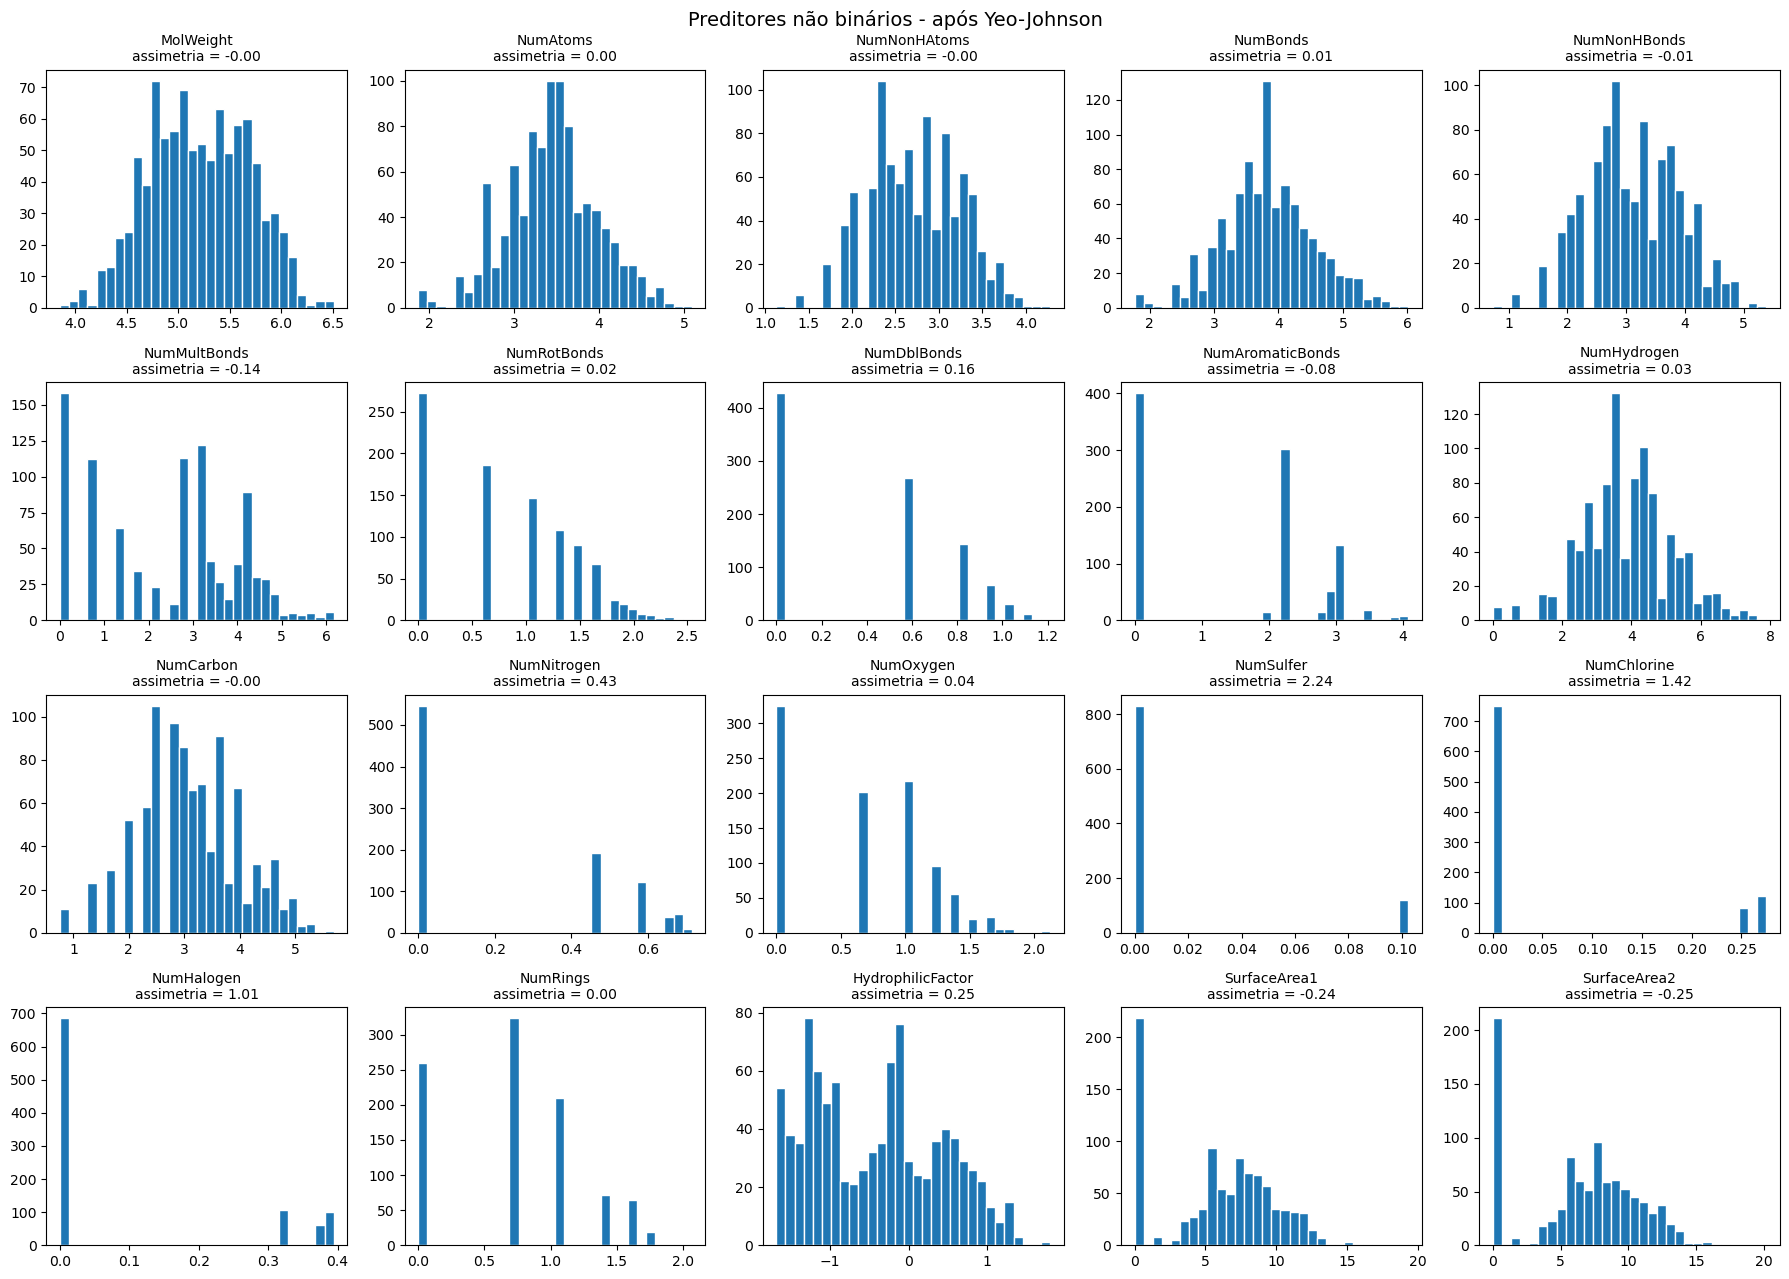

In [6]:
grade_histogramas(X_treino_t, nao_binarios, 'Preditores não binários - após Yeo-Johnson', 'hist_transformados')

A transformação resolveu a assimetria de 16 dos 20 preditores, que agora ficam com assimetria entre
-0,25 e 0,25. Vários $\lambda$ ficaram perto de zero (`MolWeight`, `NumAtoms`, `NumNonHAtoms`,
`NumRings`), o que equivale a um $\ln(x+1)$: para tamanhos moleculares a escala logarítmica é a natural.

Os que continuam assimétricos são `NumSulfer` (2,24), `NumChlorine` (1,42), `NumHalogen` (1,01) e, em
menor grau, `NumNitrogen` (0,43). Isso não é falha da transformação. Esses preditores são dominados
por zeros (a grande maioria dos compostos não tem enxofre nem cloro), e a distribuição fica parecida
com a de uma variável quase binária: um pico enorme em 0 e poucos valores espalhados acima. Uma
transformação monotônica não consegue "espalhar" um ponto único com centenas de observações, então
sempre sobra uma assimetria residual. Os $\lambda$ muito negativos dessas colunas (até -9,8 em
`NumSulfer`) são o otimizador tentando comprimir a cauda o máximo possível.

Como checagem, os arquivos `solTrainXtrans.txt`/`solTestXtrans.txt` que vêm junto com o dataset trazem
uma versão já transformada (Box-Cox, feita no pacote `caret` do R). Comparamos a assimetria dela com a nossa.

In [7]:
X_treino_ref = ler('solTrainXtrans.txt')

comparacao = pd.DataFrame({
    'nossa (Yeo-Johnson)': X_treino_t[nao_binarios].skew(),
    'fornecida (Box-Cox)': X_treino_ref[nao_binarios].skew(),
    'correlacao entre as duas': [np.corrcoef(X_treino_t[c], X_treino_ref[c])[0, 1] for c in nao_binarios],
}).round(3)
print(comparacao.to_string())

                   nossa (Yeo-Johnson)  fornecida (Box-Cox)  correlacao entre as duas
MolWeight                       -0.000               -0.000                     1.000
NumAtoms                         0.001               -0.072                     1.000
NumNonHAtoms                    -0.004               -0.056                     1.000
NumBonds                         0.005               -0.189                     0.999
NumNonHBonds                    -0.013                0.043                     1.000
NumMultBonds                    -0.142               -0.095                     1.000
NumRotBonds                      0.021                0.098                     1.000
NumDblBonds                      0.159                0.150                     1.000
NumAromaticBonds                -0.085               -0.147                     0.999
NumHydrogen                      0.029               -0.041                     1.000
NumCarbon                       -0.004                

As duas versões são praticamente equivalentes (correlação muito alta coluna a coluna) e deixam as mesmas
colunas com assimetria residual, o que confirma o diagnóstico acima. A partir daqui toda a análise usa
os nossos preditores transformados (`X_treino_t`).

## Relações entre pares de preditores

Estimamos a matriz de correlação de Pearson entre os 228 preditores transformados. Ela tem
228 x 227 / 2 = 25.878 pares distintos, então primeiro olhamos a matriz inteira como imagem e um
resumo de quantos pares têm correlação alta.

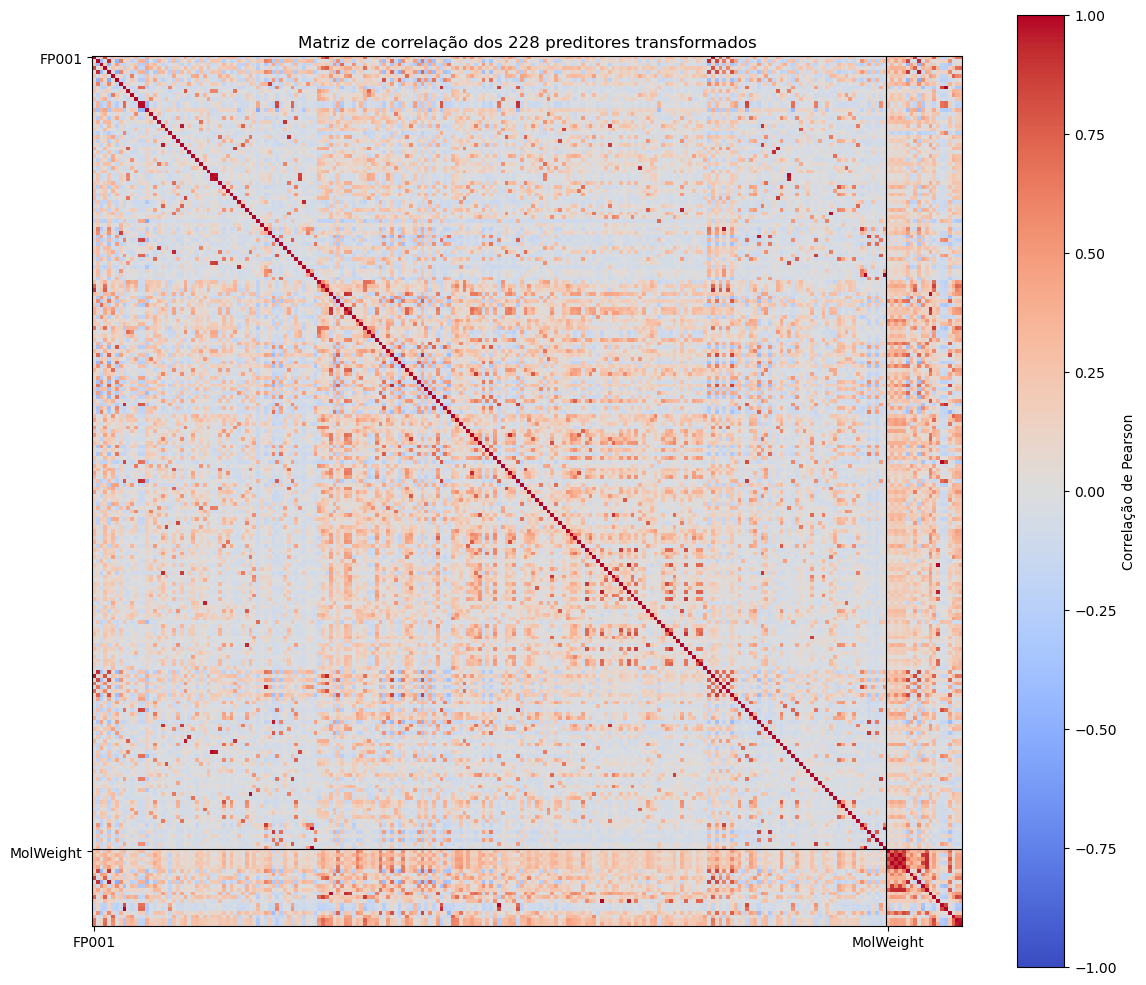

Numero de pares distintos: 25878
  pares com |r| > 0.50:  881
  pares com |r| > 0.75:  176
  pares com |r| > 0.90:   47
  pares com |r| > 0.95:   24


In [8]:
correlacao = X_treino_t.corr()

fig, ax = plt.subplots(figsize=(12, 10))
imagem = ax.imshow(correlacao, cmap='coolwarm', vmin=-1, vmax=1)
ax.axhline(len(binarios) - 0.5, color='black', lw=0.8)  # separa FP dos nao binarios
ax.axvline(len(binarios) - 0.5, color='black', lw=0.8)
ax.set_xticks([0, len(binarios)])
ax.set_xticklabels(['FP001', nao_binarios[0]])
ax.set_yticks([0, len(binarios)])
ax.set_yticklabels(['FP001', nao_binarios[0]])
fig.colorbar(imagem, ax=ax, label='Correlação de Pearson')
ax.set_title('Matriz de correlação dos 228 preditores transformados')
plt.tight_layout()
salvar_figura('matriz_correlacao_completa')
plt.show()

triangulo = np.triu(np.ones(correlacao.shape, dtype=bool), k=1)  # so os pares distintos (acima da diagonal)
pares = correlacao.where(triangulo).stack()
pares = pares.reindex(pares.abs().sort_values(ascending=False).index)

print('Numero de pares distintos:', len(pares))
for limiar in [0.5, 0.75, 0.9, 0.95]:
    print('  pares com |r| > %.2f: %4d' % (limiar, (pares.abs() > limiar).sum()))

Os 30 pares mais correlacionados:

In [9]:
print(pares.head(30).round(3).to_string())

FP134         NumSulfer           1.000
FP107         NumChlorine         0.999
NumAtoms      NumBonds            0.997
FP009         NumHalogen          0.996
FP058         FP203               0.995
              FP208               0.995
NumNonHAtoms  NumNonHBonds        0.995
FP203         FP208               0.990
FP032         FP183               0.985
FP013         FP014               0.981
FP042         FP194               0.981
FP063         NumNitrogen         0.978
FP032         FP033               0.969
FP046         FP166               0.965
FP001         FP163               0.963
FP005         NumAromaticBonds    0.962
SurfaceArea1  SurfaceArea2        0.960
FP025         FP180               0.958
FP019         FP024               0.955
FP048         FP175               0.954
FP033         FP183               0.954
FP165         FP167               0.954
FP141         NumSulfer           0.952
FP134         FP141               0.952
FP030         FP144               0.943


E o detalhe da matriz só para os 20 preditores não binários, onde dá para ler os valores:

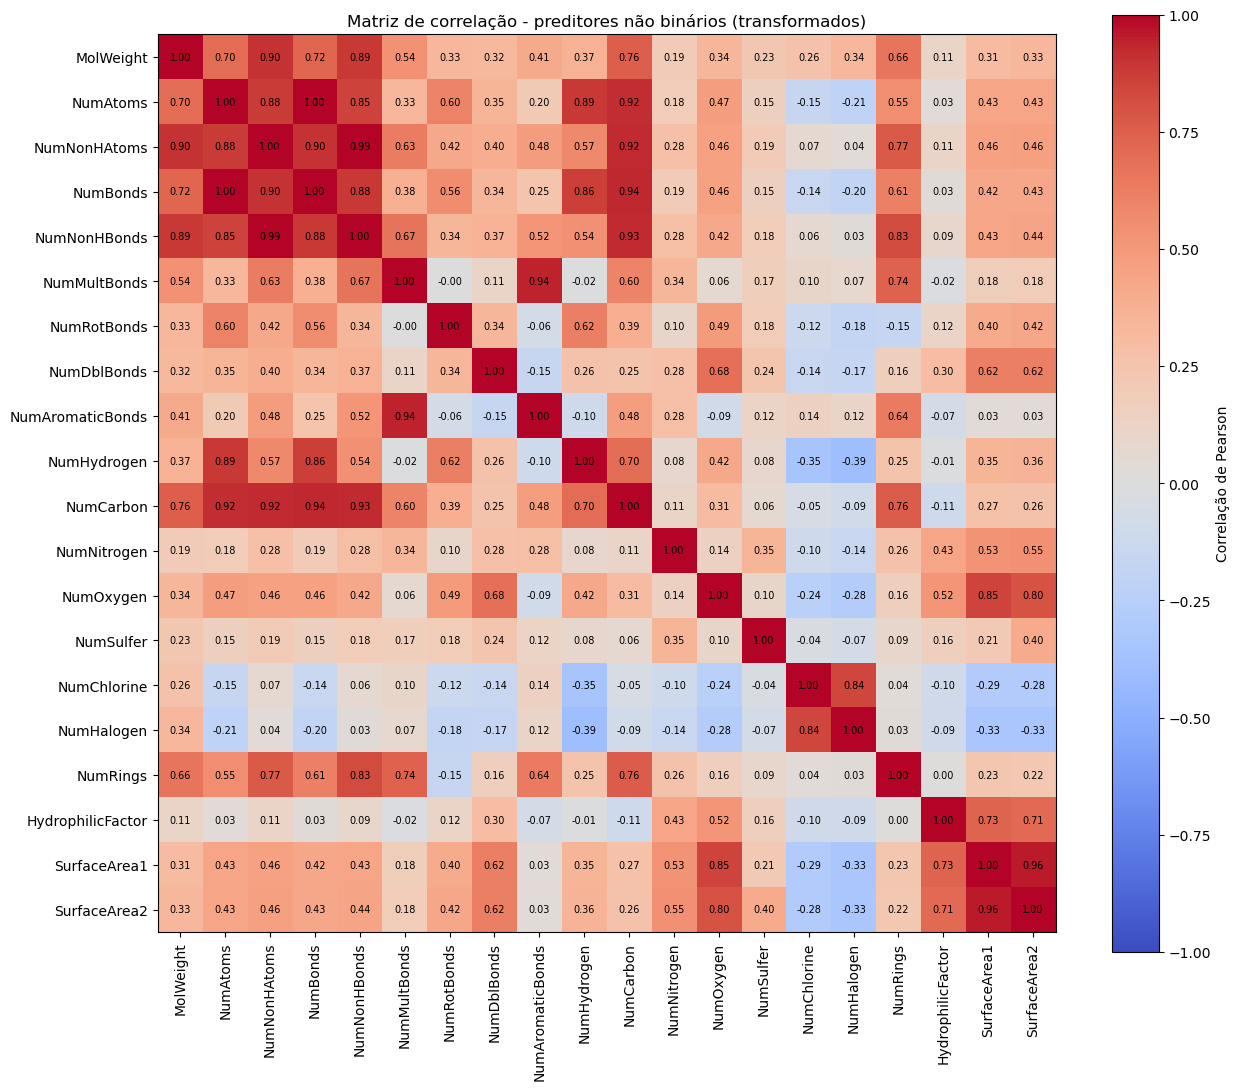

In [10]:
corr_nb = correlacao.loc[nao_binarios, nao_binarios]

fig, ax = plt.subplots(figsize=(13, 11))
imagem = ax.imshow(corr_nb, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(nao_binarios)))
ax.set_yticks(range(len(nao_binarios)))
ax.set_xticklabels(nao_binarios, rotation=90)
ax.set_yticklabels(nao_binarios)
for i in range(len(nao_binarios)):
    for j in range(len(nao_binarios)):
        ax.text(j, i, '%.2f' % corr_nb.iloc[i, j], ha='center', va='center', fontsize=7)
fig.colorbar(imagem, ax=ax, label='Correlação de Pearson')
ax.set_title('Matriz de correlação - preditores não binários (transformados)')
plt.tight_layout()
salvar_figura('matriz_correlacao_nao_binarios')
plt.show()

**Comentários sobre as relações entre preditores.**

A maior parte dos pares é fracamente correlacionada (a matriz completa é majoritariamente branca), mas
existe um grupo considerável de relações fortes: 47 pares com |r| > 0,9 e 176 com |r| > 0,75. Elas
aparecem em três situações:

1. **Preditores que medem praticamente a mesma coisa.** `NumAtoms` e `NumBonds` (r = 0,997),
   `NumNonHAtoms` e `NumNonHBonds` (0,995), `SurfaceArea1` e `SurfaceArea2` (0,96). Numa molécula, o
   número de ligações acompanha o número de átomos quase exatamente, e as duas áreas superficiais só
   diferem em alguns tipos de átomo.
2. **Fingerprint redundante com uma contagem.** `FP134` e `NumSulfer` têm correlação 1,0, `FP107` e
   `NumChlorine` 0,999, `FP009` e `NumHalogen` 0,996, `FP063` e `NumNitrogen` 0,98, `FP005` e
   `NumAromaticBonds` 0,96. Como essas contagens são quase sempre 0 ou 1, elas carregam a mesma
   informação que o fingerprint de "presença" do respectivo átomo.
3. **Fingerprints redundantes entre si.** Por exemplo `FP058`, `FP203` e `FP208` (r ≈ 0,99 entre os
   três), `FP032`/`FP183`/`FP033`, `FP013`/`FP014`. Provavelmente são subestruturas aninhadas, em que uma
   praticamente só aparece quando a outra aparece.

Entre os não binários dá para enxergar dois blocos. Um bloco de **tamanho da molécula** (`MolWeight`,
`NumAtoms`, `NumNonHAtoms`, `NumBonds`, `NumNonHBonds`, `NumCarbon`, `NumRings`), com correlações de
0,7 a 1,0 entre si; e um bloco de **polaridade** (`NumOxygen`, `NumDblBonds`, `HydrophilicFactor`,
`SurfaceArea1`, `SurfaceArea2`), com correlações entre 0,5 e 0,85. `NumMultBonds` e
`NumAromaticBonds` também andam juntos (0,94). Os halogênios (`NumChlorine`, `NumHalogen`) têm leve
correlação negativa com `NumHydrogen` (-0,35 a -0,39), já que onde há um halogênio ligado ao carbono não
há hidrogênio.

A consequência prática é que há **forte multicolinearidade** no conjunto: muitos preditores são
combinações quase lineares de outros. Isso deixa instáveis os coeficientes de uma regressão linear por
mínimos quadrados e indica que métodos com regularização (ridge, lasso) ou com redução de dimensão
(PCR, PLS), ou ainda a remoção dos preditores redundantes, tendem a funcionar melhor nesse problema.

## Relação entre cada preditor e a saída

Agora calculamos a correlação de cada um dos 228 preditores transformados com a solubilidade. Além
da correlação de Pearson, que mede só relação **linear**, calculamos a de Spearman, que mede relação
**monotônica** qualquer (é a Pearson calculada sobre os postos). Se as duas forem parecidas, a relação
é aproximadamente linear; se a Spearman for bem maior em módulo, há uma relação monotônica mas curva.
Para os binários, a correlação de Pearson é exatamente a correlação ponto-bisserial, que é o que
interessa nesse caso.

In [11]:
correlacao_saida = pd.DataFrame({
    'pearson': X_treino_t.corrwith(y_treino),
    'spearman': X_treino_t.corrwith(y_treino, method='spearman'),
    'pearson_escala_original': X_treino.corrwith(y_treino),
})

print('===== Preditores nao binarios (ordenados pela Pearson) =====')
print(correlacao_saida.loc[nao_binarios].sort_values('pearson').round(3).to_string())

print('\n===== Resumo de |r| =====')
for nome, colunas in [('nao binarios', nao_binarios), ('binarios', binarios)]:
    r = correlacao_saida.loc[colunas, 'pearson'].abs()
    print('%-13s |r| medio = %.3f   |r| max = %.3f   |r|>0.3: %3d   |r|>0.5: %2d'
          % (nome, r.mean(), r.max(), (r > 0.3).sum(), (r > 0.5).sum()))

===== Preditores nao binarios (ordenados pela Pearson) =====
                   pearson  spearman  pearson_escala_original
MolWeight           -0.659    -0.685                   -0.629
NumCarbon           -0.607    -0.674                   -0.583
NumNonHBonds        -0.585    -0.632                   -0.551
NumNonHAtoms        -0.583    -0.630                   -0.545
NumRings            -0.481    -0.509                   -0.488
NumMultBonds        -0.476    -0.480                   -0.525
NumBonds            -0.459    -0.548                   -0.420
NumAtoms            -0.436    -0.520                   -0.399
NumAromaticBonds    -0.425    -0.458                   -0.516
NumHalogen          -0.387    -0.381                   -0.504
NumChlorine         -0.377    -0.357                   -0.504
NumHydrogen         -0.154    -0.256                   -0.204
NumRotBonds         -0.112    -0.150                   -0.149
NumSulfer           -0.073    -0.121                   -0.091
NumDblBon

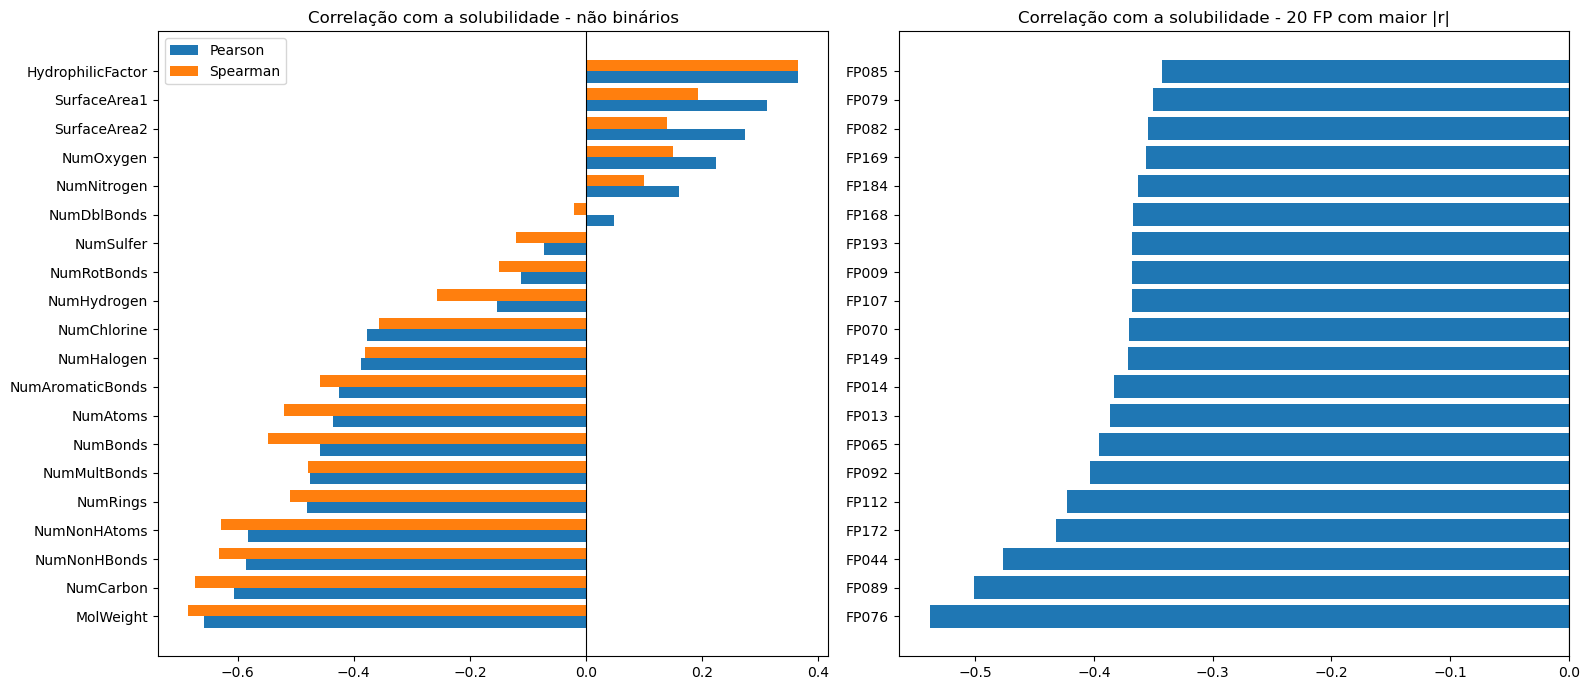

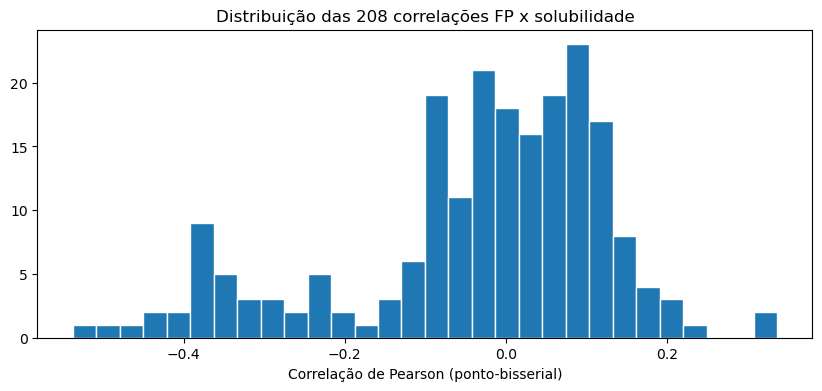

In [12]:
ordem = correlacao_saida['pearson'].sort_values()
top_fp = correlacao_saida.loc[binarios, 'pearson'].abs().sort_values(ascending=False).index[:20]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
dados_nb = correlacao_saida.loc[nao_binarios].sort_values('pearson')
posicoes = np.arange(len(dados_nb))
axes[0].barh(posicoes - 0.2, dados_nb['pearson'], height=0.4, label='Pearson')
axes[0].barh(posicoes + 0.2, dados_nb['spearman'], height=0.4, label='Spearman')
axes[0].set_yticks(posicoes)
axes[0].set_yticklabels(dados_nb.index)
axes[0].axvline(0, color='black', lw=0.8)
axes[0].set_title('Correlação com a solubilidade - não binários')
axes[0].legend()

dados_fp = correlacao_saida.loc[top_fp].sort_values('pearson')
axes[1].barh(range(len(dados_fp)), dados_fp['pearson'])
axes[1].set_yticks(range(len(dados_fp)))
axes[1].set_yticklabels(dados_fp.index)
axes[1].axvline(0, color='black', lw=0.8)
axes[1].set_title('Correlação com a solubilidade - 20 FP com maior |r|')
plt.tight_layout()
salvar_figura('correlacao_preditor_saida')
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(correlacao_saida.loc[binarios, 'pearson'], bins=30, edgecolor='white')
ax.set_title('Distribuição das 208 correlações FP x solubilidade')
ax.set_xlabel('Correlação de Pearson (ponto-bisserial)')
salvar_figura('hist_correlacao_fp_saida')
plt.show()

A correlação só mede a força da tendência linear; para ver a **forma** da relação, plotamos a
solubilidade contra cada preditor não binário transformado. Em cada painel desenhamos a reta de mínimos
quadrados (vermelho) e um ajuste quadrático (verde). Se a curva verde se afasta da reta, a relação tem
curvatura.

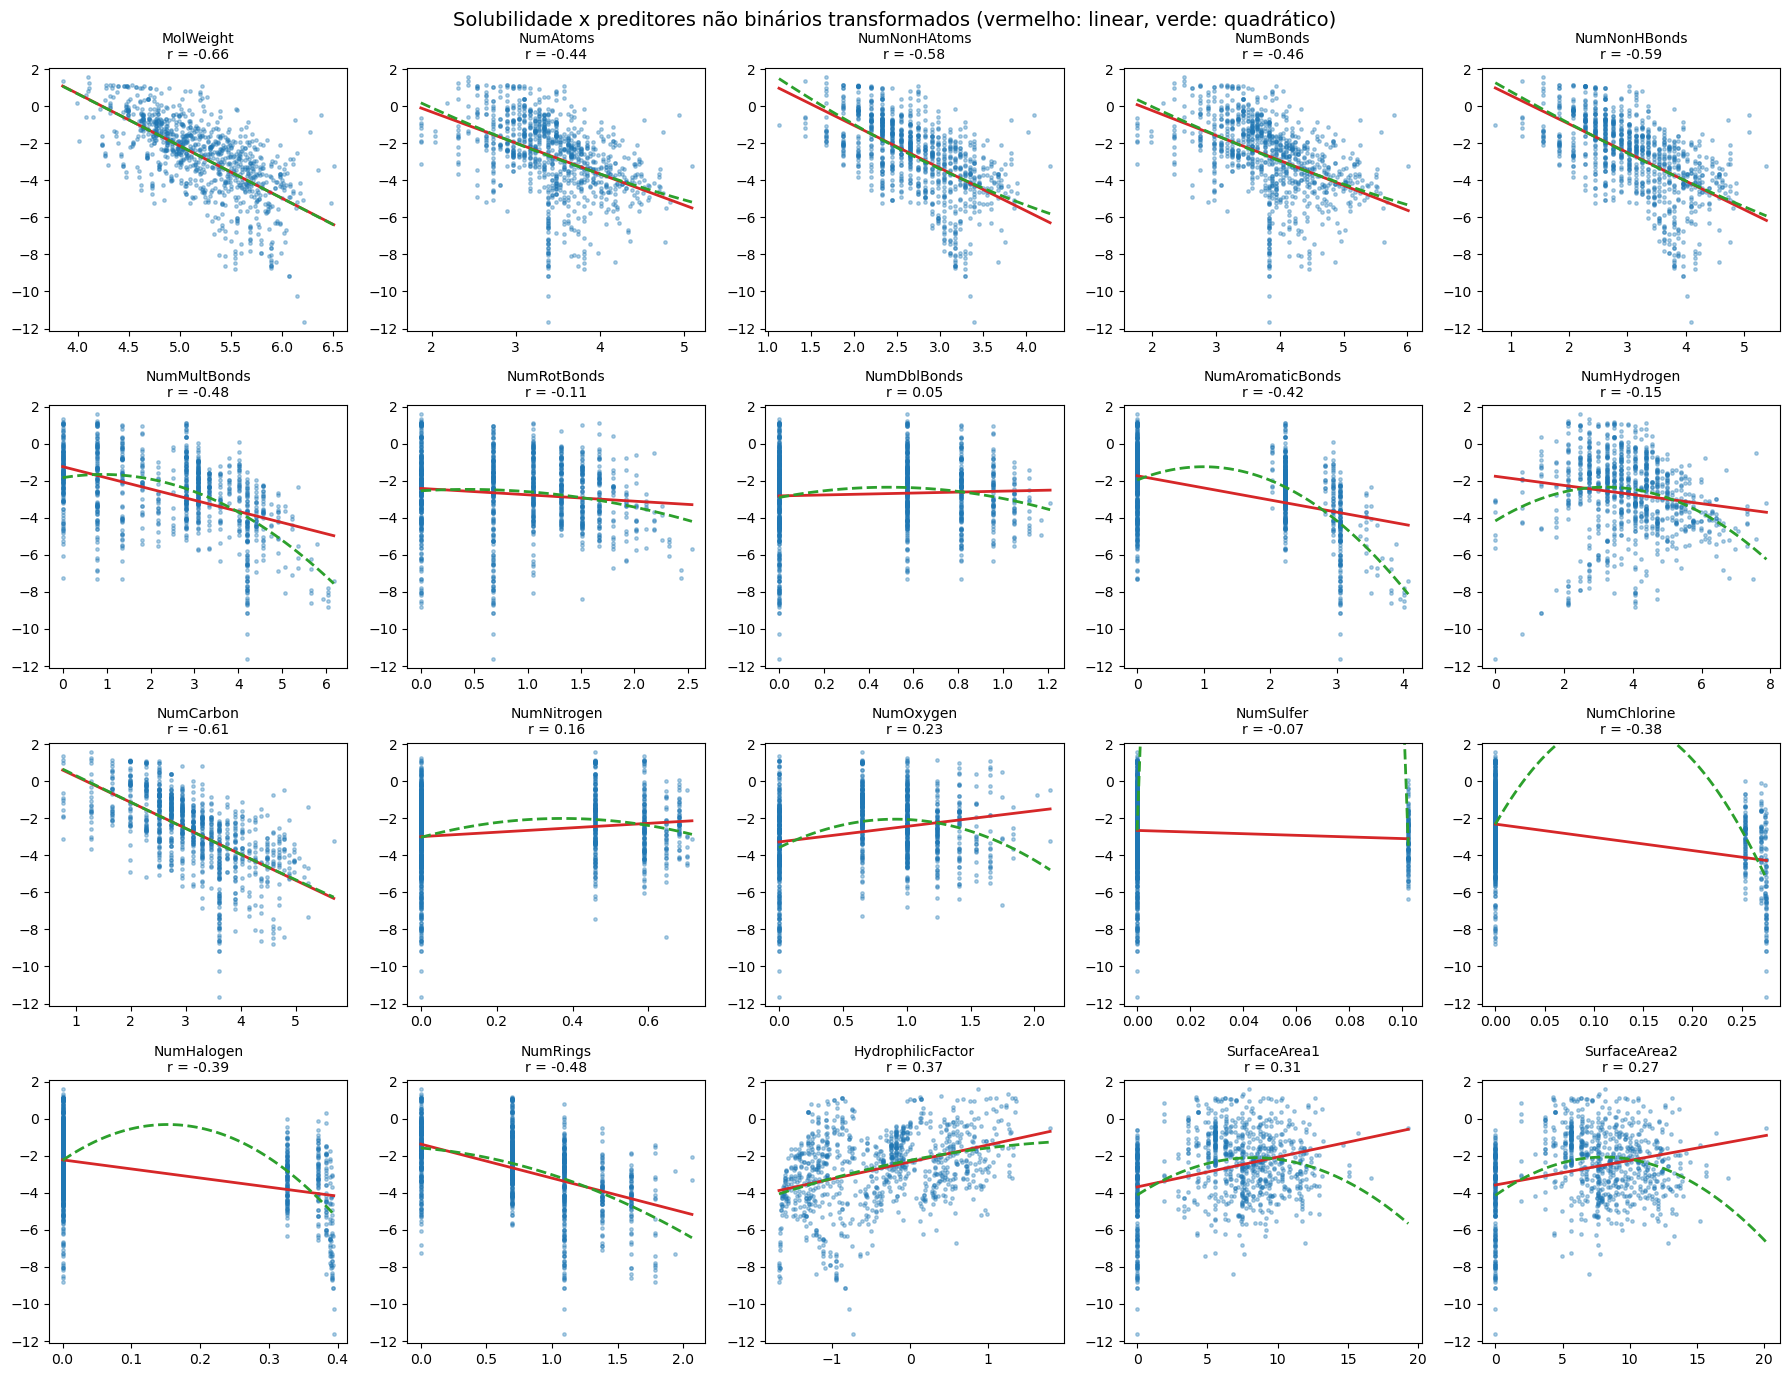

                   R2_linear  R2_quadratico  ganho_quadratico
NumAromaticBonds       0.181          0.310             0.129
SurfaceArea2           0.075          0.161             0.085
NumMultBonds           0.227          0.289             0.062
NumOxygen              0.051          0.111             0.060
SurfaceArea1           0.097          0.154             0.057
NumHydrogen            0.024          0.072             0.049
NumChlorine            0.142          0.189             0.047
NumHalogen             0.150          0.193             0.043
NumRings               0.231          0.246             0.015
NumDblBonds            0.002          0.015             0.013
NumNitrogen            0.026          0.038             0.012
NumRotBonds            0.013          0.019             0.006
HydrophilicFactor      0.133          0.136             0.002
NumNonHAtoms           0.340          0.341             0.001
NumSulfer              0.005          0.006             0.001
NumAtoms

In [13]:
fig, axes = plt.subplots(4, 5, figsize=(18, 14))
r2_linear, r2_quadratico = {}, {}
variancia_y = np.var(y_treino)

for ax, coluna in zip(axes.ravel(), nao_binarios):
    x = X_treino_t[coluna].values
    grade = np.linspace(x.min(), x.max(), 100)
    coef1 = np.polyfit(x, y_treino, 1)
    coef2 = np.polyfit(x, y_treino, 2)
    r2_linear[coluna] = 1 - np.var(y_treino - np.polyval(coef1, x)) / variancia_y
    r2_quadratico[coluna] = 1 - np.var(y_treino - np.polyval(coef2, x)) / variancia_y

    ax.scatter(x, y_treino, s=6, alpha=0.35)
    ax.plot(grade, np.polyval(coef1, grade), color='tab:red', lw=2)
    ax.plot(grade, np.polyval(coef2, grade), color='tab:green', lw=2, ls='--')
    ax.set_ylim(y_treino.min() - 0.5, y_treino.max() + 0.5)  # mesma escala da saida em todos os paineis
    ax.set_title('%s\nr = %.2f' % (coluna, correlacao_saida.loc[coluna, 'pearson']), fontsize=10)

fig.suptitle('Solubilidade x preditores não binários transformados (vermelho: linear, verde: quadrático)', fontsize=14)
plt.tight_layout()
salvar_figura('scatter_preditores_saida')
plt.show()

tabela_r2 = pd.DataFrame({'R2_linear': r2_linear, 'R2_quadratico': r2_quadratico})
tabela_r2['ganho_quadratico'] = tabela_r2['R2_quadratico'] - tabela_r2['R2_linear']
print(tabela_r2.sort_values('ganho_quadratico', ascending=False).round(3).to_string())

Para os binários, o gráfico equivalente é o boxplot da solubilidade nos dois grupos (subestrutura
ausente x presente). Mostramos os 8 fingerprints com maior |r|.

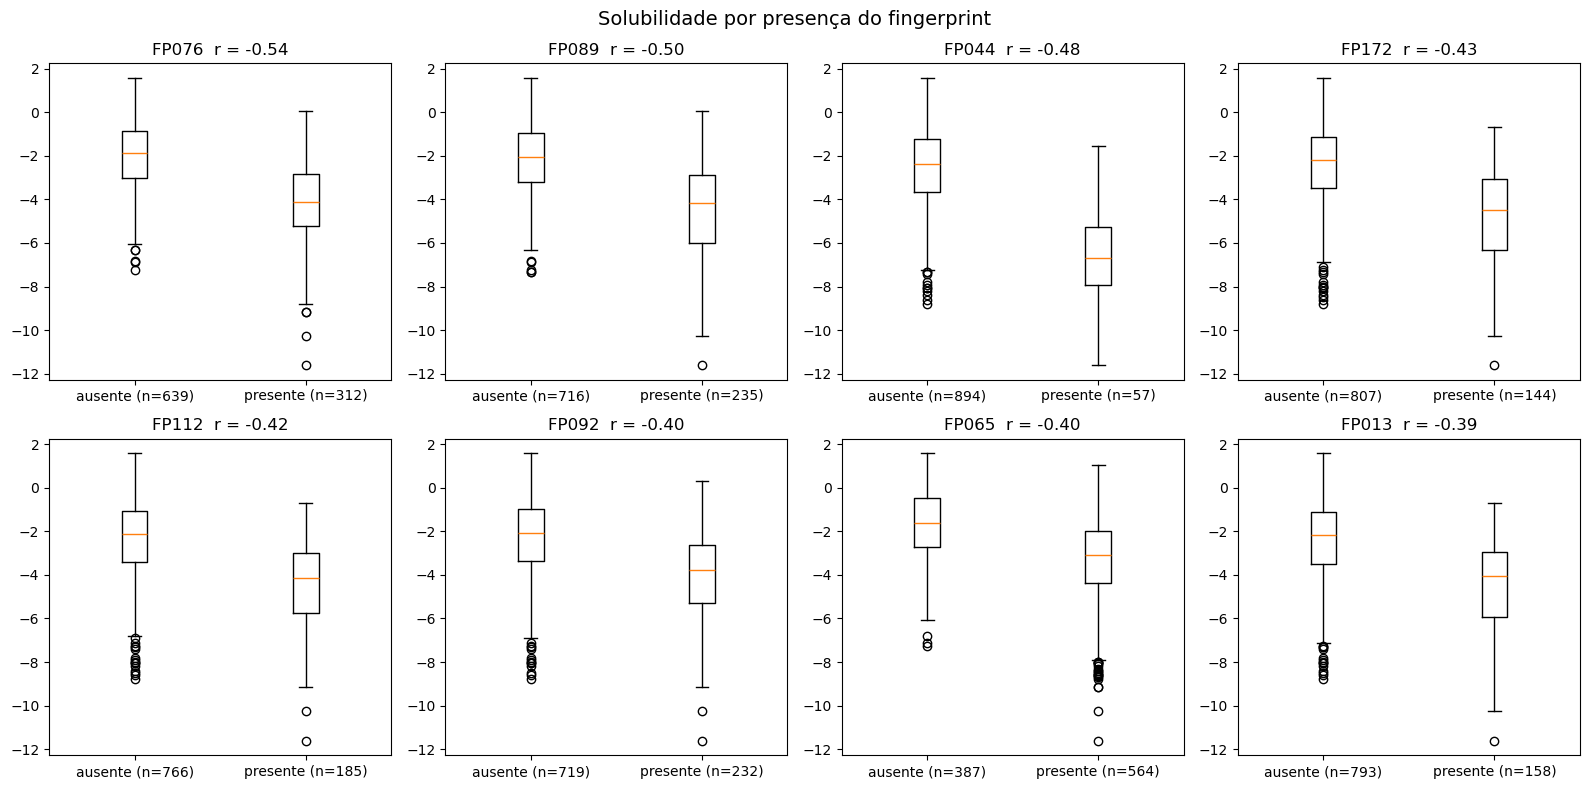

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, coluna in zip(axes.ravel(), top_fp[:8]):
    grupos = [y_treino[X_treino_t[coluna] == 0], y_treino[X_treino_t[coluna] == 1]]
    ax.boxplot(grupos)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['ausente (n=%d)' % len(grupos[0]), 'presente (n=%d)' % len(grupos[1])])
    ax.set_title('%s  r = %.2f' % (coluna, correlacao_saida.loc[coluna, 'pearson']))
fig.suptitle('Solubilidade por presença do fingerprint', fontsize=14)
plt.tight_layout()
salvar_figura('boxplot_fp_saida')
plt.show()

**Comentários sobre as relações preditor x saída.**

*Preditores não binários.* As relações mais fortes são todas **negativas** e vêm do bloco de tamanho
molecular: `MolWeight` (r = -0,66), `NumCarbon` (-0,61), `NumNonHBonds` e `NumNonHAtoms` (-0,58),
seguidos de `NumRings`, `NumMultBonds`, `NumBonds`, `NumAtoms`, `NumAromaticBonds` e dos halogênios
(entre -0,38 e -0,48). Faz sentido químico: moléculas maiores, mais aromáticas e com halogênios são mais
hidrofóbicas e se dissolvem menos em água. Do outro lado, os preditores de polaridade têm correlação
**positiva** com a solubilidade, mas fraca: `HydrophilicFactor` (0,37), `SurfaceArea1` (0,31),
`SurfaceArea2` (0,27) e `NumOxygen` (0,23). `NumDblBonds`, `NumSulfer`, `NumRotBonds` e `NumHydrogen`
praticamente não têm relação individual com a saída (|r| < 0,16). Nenhum preditor sozinho explica mais
que cerca de 43% da variância da solubilidade (r² de `MolWeight`).

*São relações lineares?* Para os preditores mais importantes, sim, aproximadamente. Nos preditores de
tamanho (`MolWeight`, `NumCarbon`, `NumNonHAtoms`, `NumNonHBonds`, `NumAtoms`, `NumBonds`) o ajuste
quadrático coincide com a reta e o ganho de R² é zero, ou seja, depois da transformação a relação é
linear. A transformação ajudou nesses casos: a |r| de `MolWeight` passou de 0,63 na escala original
para 0,66, a de `NumNonHAtoms` de 0,55 para 0,58 e a de `NumAtoms` de 0,40 para 0,44. Em outros ela
piorou a correlação linear: `NumMultBonds` (0,53 para 0,48), `NumAromaticBonds` (0,52 para 0,43) e os
halogênios (0,50 para 0,38). Remover a assimetria não garante uma relação mais linear com a saída; nesses
preditores a relação já era mais linear na escala original.

Há, porém, preditores com **curvatura clara**, onde a quadrática melhora o ajuste de forma relevante:
`NumAromaticBonds` (R² vai de 0,18 para 0,31), `SurfaceArea2` (0,08 para 0,16), `NumMultBonds`
(0,23 para 0,29), `NumOxygen` e `SurfaceArea1` (cerca de +0,06) e `NumHydrogen` (+0,05).

- Em `NumAromaticBonds` e `NumMultBonds` a solubilidade fica praticamente constante entre 0 e um anel
  aromático (6 ligações) e só cai a partir de dois ou mais anéis: a relação é plana e depois decrescente.
- Em `SurfaceArea1`/`SurfaceArea2` há um grupo de compostos com área zero e solubilidade baixa; a partir
  daí a solubilidade sobe com a área e depois se estabiliza ou cai. A relação não é monotônica, o que
  aparece também no fato de a Pearson (0,31/0,27) ser maior que a Spearman (0,19/0,14).
- Em `NumHydrogen` e `NumOxygen` a solubilidade sobe e depois desce (forma de U invertido).
- Em `NumBonds`, `NumAtoms` e `NumHydrogen` a Spearman é bem maior em módulo que a Pearson, sinal de uma
  relação monotônica mas não exatamente linear.

Um cuidado: em `NumSulfer`, `NumChlorine` e `NumHalogen` o ganho da quadrática (até +0,05) não deve ser
lido como curvatura. Na escala original eles vão de 0 a 4 (enxofre) ou de 0 a 10 (cloro e halogênios),
mas o $\lambda$ muito negativo estimado pela Yeo-Johnson comprime todos os valores maiores ou iguais a 1
em praticamente um único ponto (no `NumSulfer`, por exemplo, 1, 2, 3 e 4 viram todos algo perto de 0,10).
Depois da transformação sobram, na prática, só dois ou três aglomerados de pontos, e a parábola apenas
interpola a média de cada aglomerado; no `NumSulfer` ela é quase indeterminada e sai da escala do gráfico.
Isso também explica por que a correlação desses preditores com a saída caiu após a transformação: a
informação de "quantos" átomos de halogênio existem foi praticamente apagada, e eles passaram a se
comportar como variáveis binárias, iguais aos fingerprints correspondentes (`FP107`, `FP009`, `FP134`).
Para esses três preditores a escala original provavelmente é a mais útil para a modelagem.

*Preditores binários.* A maioria dos fingerprints tem relação fraca com a solubilidade (|r| médio de
0,12, mediana 0,09), mas alguns são bem informativos: `FP076` (-0,54), `FP089` (-0,50), `FP044` (-0,48),
`FP172` (-0,43), `FP112` (-0,42) e, com sinal positivo, `FP072` (0,34) e `FP015` (0,33). Para um
preditor binário a pergunta de linearidade não se aplica no mesmo sentido: com dois níveis, a relação é
sempre exatamente uma reta ligando as duas médias, e a correlação mede só a diferença entre elas.

*Resumo.* Após a transformação, as relações individuais entre preditores e saída são majoritariamente
lineares (especialmente para os preditores mais correlacionados com a solubilidade), mas não todas:
alguns descritores apresentam curvatura e até relação não monotônica. Somado à forte
multicolinearidade observada antes, isso sugere que modelos lineares regularizados devem capturar
boa parte do sinal, enquanto modelos não lineares podem ganhar justamente nesses preditores curvos.